# Home Loan Default Prediction

## Project Objective
Build an interpretable and robust machine-learning system to predict whether a loan applicant is likely to default (`TARGET = 1`) or not default (`TARGET = 0`). The project combines the main application table with historical bureau, previous-application, POS-CASH, credit-card and installment-payment information.

## Business Objective
The priority is **early identification of risky applicants**, so accuracy alone is not an appropriate success criterion because the target is highly imbalanced. Model selection therefore emphasizes **ROC-AUC, PR-AUC, recall, F1-score and confusion-matrix analysis** for the default class.

## Quality Controls in This Notebook
- EDA covers both numerical and categorical variables and records data-driven observations.
- Outliers are **diagnosed rather than deleted blindly**; legitimate financial extremes are retained.
- The `DAYS_EMPLOYED = 365243` sentinel is treated as missing.
- Model preprocessing (imputation, encoding and scaling) is fitted **only on training data** to prevent leakage.
- Highly correlated numerical predictors are screened using the training set only.
- Regularized Logistic Regression is included as a linear baseline.
- Random Forest and XGBoost are tuned using stratified cross-validation.
- The final threshold is selected on a validation set, never on the test set.


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
application_train = pd.read_csv('application_train.csv')
bureau = pd.read_csv('bureau.csv')
bureau_balance = pd.read_csv('bureau_balance.csv')
pos_cash_balance = pd.read_csv('POS_CASH_balance.csv')
credit_card_balance = pd.read_csv('credit_card_balance.csv')
previous_application = pd.read_csv('previous_application.csv')
installments_payments = pd.read_csv('installments_payments.csv')

In [6]:
datasets = {
    'application_train': application_train,
    'bureau': bureau,
    'bureau_balance': bureau_balance,
    'POS_CASH_balance': pos_cash_balance,
    'credit_card_balance': credit_card_balance,
    'previous_application': previous_application,
    'installments_payments': installments_payments
}

In [8]:
for name, df in datasets.items():
    print(name, type(df), df.shape)

application_train <class 'pandas.core.frame.DataFrame'> (307511, 122)
bureau <class 'pandas.core.frame.DataFrame'> (1716428, 17)
bureau_balance <class 'pandas.core.frame.DataFrame'> (27299925, 3)
POS_CASH_balance <class 'pandas.core.frame.DataFrame'> (10001358, 8)
credit_card_balance <class 'pandas.core.frame.DataFrame'> (3840312, 23)
previous_application <class 'pandas.core.frame.DataFrame'> (1670214, 37)
installments_payments <class 'pandas.core.frame.DataFrame'> (13605401, 8)


In [10]:
for name, df in datasets.items():
    print("\n" + "="*80)
    print(name)
    print("="*80)
    display(df.head())


application_train


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0



bureau


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN



bureau_balance


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


... (4 outputs left out)


previous_application


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN



installments_payments


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


In [12]:
for name, df in datasets.items():
    print(name, "→ Duplicate rows:", df.duplicated().sum())

application_train → Duplicate rows: 0
bureau → Duplicate rows: 0
bureau_balance → Duplicate rows: 0
POS_CASH_balance → Duplicate rows: 0
credit_card_balance → Duplicate rows: 0
previous_application → Duplicate rows: 0
installments_payments → Duplicate rows: 0


In [13]:
for name, df in datasets.items():
    print("\n" + "="*80)
    print(name)
    print("="*80)
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    display(pd.DataFrame({
        'Missing_Count': missing,
        'Missing_Percentage': (missing / len(df) * 100).round(2)
    }).head(20))


application_train


,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.87
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_MODE,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_AVG,210199,68.35



bureau


,Missing_Count,Missing_Percentage
AMT_ANNUITY,1226791,71.47
AMT_CREDIT_MAX_OVERDUE,1124488,65.51
DAYS_ENDDATE_FACT,633653,36.92
AMT_CREDIT_SUM_LIMIT,591780,34.48
AMT_CREDIT_SUM_DEBT,257669,15.01
DAYS_CREDIT_ENDDATE,105553,6.15
AMT_CREDIT_SUM,13,0.00



bureau_balance


,Missing_Count,Missing_Percentage


... (4 outputs left out)


previous_application


,Missing_Count,Missing_Percentage
RATE_INTEREST_PRIMARY,1664263,99.64
RATE_INTEREST_PRIVILEGED,1664263,99.64
AMT_DOWN_PAYMENT,895844,53.64
RATE_DOWN_PAYMENT,895844,53.64
NAME_TYPE_SUITE,820405,49.12
DAYS_FIRST_DRAWING,673065,40.30
DAYS_FIRST_DUE,673065,40.30
DAYS_LAST_DUE_1ST_VERSION,673065,40.30
DAYS_LAST_DUE,673065,40.30
DAYS_TERMINATION,673065,40.30



installments_payments


,Missing_Count,Missing_Percentage
DAYS_ENTRY_PAYMENT,2905,0.02
AMT_PAYMENT,2905,0.02


In [16]:
print(application_train['TARGET'].value_counts())
print()
print((application_train['TARGET'].value_counts(normalize=True) * 100).round(2))

TARGET
0    282686
1     24825
Name: count, dtype: int64

TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [18]:

continuous_candidates = application_train.select_dtypes(include=np.number).columns.tolist()
exclude_cols = ['SK_ID_CURR', 'TARGET'] + [
    c for c in continuous_candidates
    if application_train[c].nunique(dropna=True) <= 10
]
continuous_cols = [c for c in continuous_candidates if c not in exclude_cols]

outlier_summary = []
for col in continuous_cols:
    q1 = application_train[col].quantile(0.25)
    q3 = application_train[col].quantile(0.75)
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        continue
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((application_train[col] < lower) | (application_train[col] > upper)).sum()
    outlier_summary.append({
        'Column': col,
        'Outliers': int(count),
        'Outlier_Percentage': round(100 * count / len(application_train), 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values('Outlier_Percentage', ascending=False)
print('Top continuous-variable outlier rates:')
display(outlier_df.head(20))
print('\nOutlier policy: no observations are removed solely because they fall outside IQR limits.')


Top continuous-variable outlier rates:


,Column,Outliers,Outlier_Percentage
7,DAYS_EMPLOYED,72217,23.48
59,OBS_30_CNT_SOCIAL_CIRCLE,19971,6.49
60,OBS_60_CNT_SOCIAL_CIRCLE,19564,6.36
43,NONLIVINGAREA_MODE,18817,6.12
57,NONLIVINGAREA_MEDI,17254,5.61
29,NONLIVINGAREA_AVG,16546,5.38
28,NONLIVINGAPARTMENTS_AVG,15580,5.07
56,NONLIVINGAPARTMENTS_MEDI,15215,4.95
4,AMT_GOODS_PRICE,14728,4.79
42,NONLIVINGAPARTMENTS_MODE,14224,4.63



Outlier policy: no observations are removed solely because they fall outside IQR limits.


In [20]:
application_train_clean = application_train.copy()
bureau_clean = bureau.copy()
bureau_balance_clean = bureau_balance.copy()
pos_cash_balance_clean = pos_cash_balance.copy()
credit_card_balance_clean = credit_card_balance.copy()
previous_application_clean = previous_application.copy()
installments_payments_clean = installments_payments.copy()

In [22]:
if 'DAYS_EMPLOYED' in application_train_clean.columns:
    sentinel_count = (application_train_clean['DAYS_EMPLOYED'] == 365243).sum()
    application_train_clean['DAYS_EMPLOYED'] = application_train_clean['DAYS_EMPLOYED'].replace(365243, np.nan)
    print(f'DAYS_EMPLOYED sentinel values converted to NaN: {sentinel_count:,}')


DAYS_EMPLOYED sentinel values converted to NaN: 55,374


In [24]:
missing_threshold = 50

missing_percent = application_train_clean.isnull().mean() * 100

cols_to_drop = missing_percent[missing_percent > missing_threshold].index

print("Number of columns to drop:", len(cols_to_drop))
print("\nColumns to drop:")
print(cols_to_drop.tolist())

Number of columns to drop: 41

Columns to drop:
['OWN_CAR_AGE', 'EXT_SOURCE_1', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']


In [26]:
application_train_clean = application_train_clean.drop(columns=cols_to_drop)

In [28]:
numeric_cols = application_train_clean.select_dtypes(include=np.number).columns
for col in numeric_cols:
    application_train_clean[col] = application_train_clean[col].fillna(
        application_train_clean[col].median()
    )

In [29]:
categorical_cols = application_train_clean.select_dtypes(include='object').columns
for col in categorical_cols:
    application_train_clean[col] = application_train_clean[col].fillna('Unknown')

In [31]:
missing_after = application_train_clean.isnull().sum()
missing_after = missing_after[missing_after > 0].sort_values(ascending=False)
print("Remaining missing values:")
print(missing_after)

Remaining missing values:
Series([], dtype: int64)


In [34]:
num_cols = bureau_clean.select_dtypes(include=np.number).columns
cat_cols = bureau_clean.select_dtypes(include='object').columns

In [36]:
for col in num_cols:
    bureau_clean[col] = bureau_clean[col].fillna(
        bureau_clean[col].median()
    )

In [38]:
for col in cat_cols:
    bureau_clean[col] = bureau_clean[col].fillna('Unknown')

In [40]:
print("Remaining missing values:")
print(bureau_clean.isnull().sum()[bureau_clean.isnull().sum() > 0])

Remaining missing values:
Series([], dtype: int64)


In [41]:
bureau_balance_clean = bureau_balance.copy()
print(bureau_balance_clean.isnull().sum().sum())

0


In [43]:
pos_cash_balance_clean = pos_cash_balance.copy()
num_cols = pos_cash_balance_clean.select_dtypes(include=np.number).columns
for col in num_cols:
    pos_cash_balance_clean[col] = pos_cash_balance_clean[col].fillna(
        pos_cash_balance_clean[col].median()
    )

cat_cols = pos_cash_balance_clean.select_dtypes(include='object').columns
for col in cat_cols:
    pos_cash_balance_clean[col] = pos_cash_balance_clean[col].fillna('Unknown')

In [44]:
print(pos_cash_balance_clean.isnull().sum().sum())

0


In [46]:
credit_card_balance_clean = credit_card_balance.copy()
num_cols = credit_card_balance_clean.select_dtypes(include=np.number).columns
for col in num_cols:
    credit_card_balance_clean[col] = credit_card_balance_clean[col].fillna(
        credit_card_balance_clean[col].median()
    )
cat_cols = credit_card_balance_clean.select_dtypes(include='object').columns
for col in cat_cols:
    credit_card_balance_clean[col] = credit_card_balance_clean[col].fillna('Unknown')

In [47]:
print(credit_card_balance_clean.isnull().sum().sum())

0


In [48]:
installments_payments_clean = installments_payments.copy()
num_cols = installments_payments_clean.select_dtypes(include=np.number).columns
for col in num_cols:
    installments_payments_clean[col] = installments_payments_clean[col].fillna(
        installments_payments_clean[col].median()
    )

In [49]:
print(installments_payments_clean.isnull().sum().sum())

0


In [50]:
missing_pct = previous_application_clean.isnull().mean() * 100
print(
    missing_pct[missing_pct > 90]
    .sort_values(ascending=False)
)

RATE_INTEREST_PRIMARY       99.643698
RATE_INTEREST_PRIVILEGED    99.643698
dtype: float64


In [58]:
previous_application_clean = previous_application_clean.drop(
    columns=['RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED']
)

In [59]:
num_cols = previous_application_clean.select_dtypes(include=np.number).columns

for col in num_cols:
    previous_application_clean[col] = previous_application_clean[col].fillna(
        previous_application_clean[col].median()
    )

In [61]:
cat_cols = previous_application_clean.select_dtypes(include='object').columns
for col in cat_cols:
    previous_application_clean[col] = previous_application_clean[col].fillna(
        'Unknown'
    )

In [63]:
clean_datasets = {
    'application_train': application_train_clean,
    'bureau': bureau_clean,
    'bureau_balance': bureau_balance_clean,
    'POS_CASH_balance': pos_cash_balance_clean,
    'credit_card_balance': credit_card_balance_clean,
    'previous_application': previous_application_clean,
    'installments_payments': installments_payments_clean
}

for name, df in clean_datasets.items():
    print(name, "→ Missing values:", df.isnull().sum().sum())

application_train → Missing values: 0
bureau → Missing values: 0
bureau_balance → Missing values: 0
POS_CASH_balance → Missing values: 0
credit_card_balance → Missing values: 0
previous_application → Missing values: 0
installments_payments → Missing values: 0


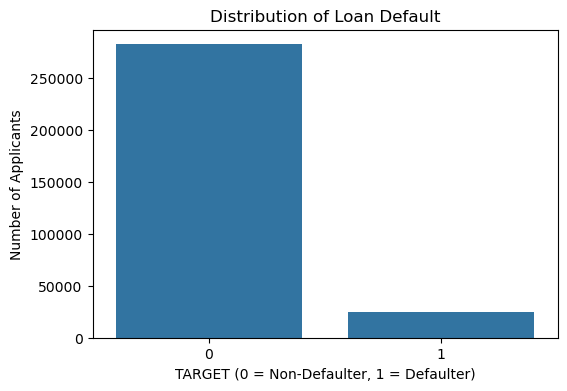

In [66]:
plt.figure(figsize=(6, 4))
sns.countplot(data=application_train_clean, x='TARGET')
plt.title('Distribution of Loan Default')
plt.xlabel('TARGET (0 = Non-Defaulter, 1 = Defaulter)')
plt.ylabel('Number of Applicants')
plt.show()

In [68]:
target_counts = application_train_clean['TARGET'].value_counts()
print("Non-Defaulters (0):", target_counts[0])
print("Defaulters (1):", target_counts[1])
print("\nPercentage:")
print(
    (application_train_clean['TARGET']
     .value_counts(normalize=True) * 100).round(2)
)

Non-Defaulters (0): 282686
Defaulters (1): 24825

Percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


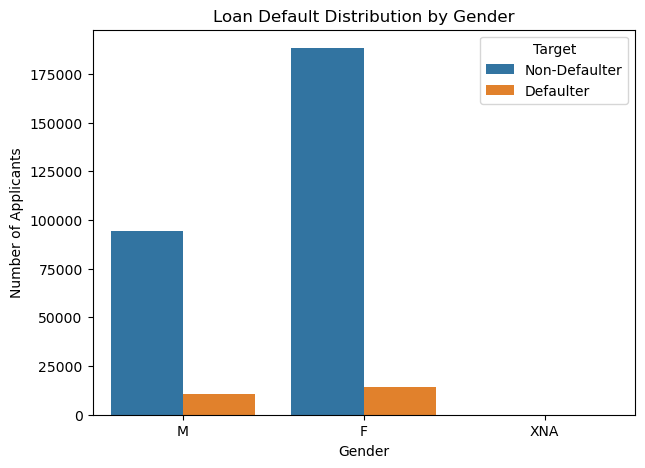

In [70]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=application_train_clean,
    x='CODE_GENDER',
    hue='TARGET'
)
plt.title('Loan Default Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Applicants')
plt.legend(
    title='Target',
    labels=['Non-Defaulter', 'Defaulter']
)
plt.show()

## EDA — Categorical Variables and Default Rates
Counts alone can hide the effect of class imbalance. For each important categorical variable, we therefore examine both the distribution and the **default rate within each category**. The code below prints the most/least risky groups so the charts are accompanied by explicit observations.



NAME_CONTRACT_TYPE — highest default-rate categories:


,count,default_rate
NAME_CONTRACT_TYPE,,
Cash loans,278232,8.35
Revolving loans,29279,5.48


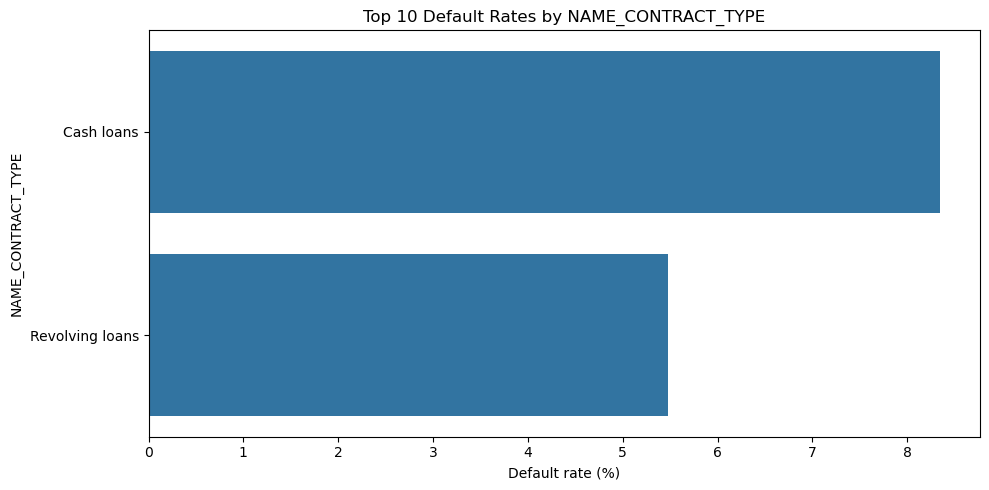


CODE_GENDER — highest default-rate categories:


,count,default_rate
CODE_GENDER,,
M,105059,10.14
F,202448,7.00
XNA,4,0.00


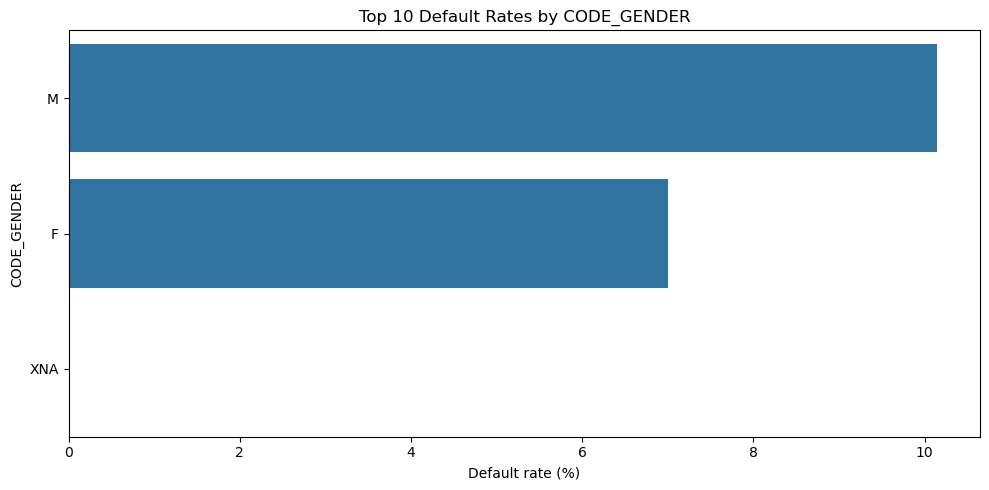


NAME_INCOME_TYPE — highest default-rate categories:


,count,default_rate
NAME_INCOME_TYPE,,
Maternity leave,5,40.00
Unemployed,22,36.36
Working,158774,9.59
Commercial associate,71617,7.48
State servant,21703,5.75
Pensioner,55362,5.39
Businessman,10,0.00
Student,18,0.00


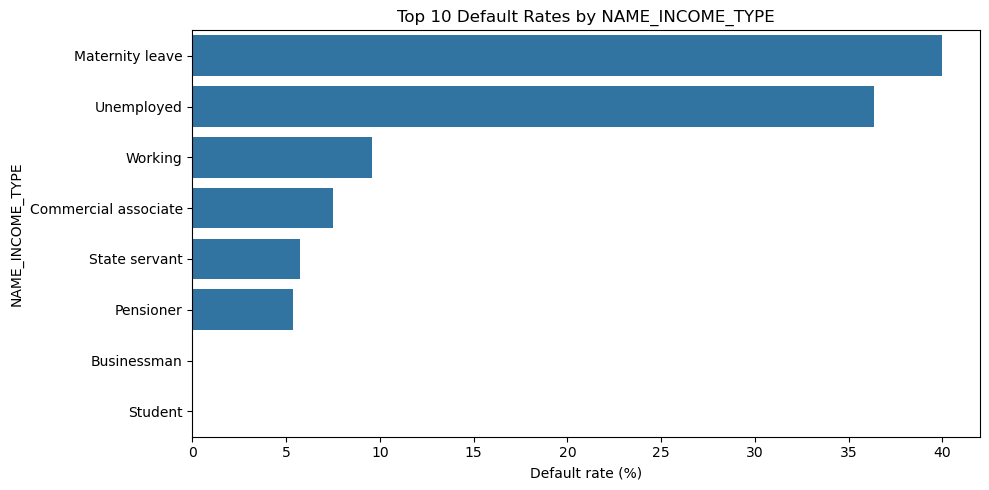


NAME_EDUCATION_TYPE — highest default-rate categories:


,count,default_rate
NAME_EDUCATION_TYPE,,
Lower secondary,3816,10.93
Secondary / secondary special,218391,8.94
Incomplete higher,10277,8.48
Higher education,74863,5.36
Academic degree,164,1.83


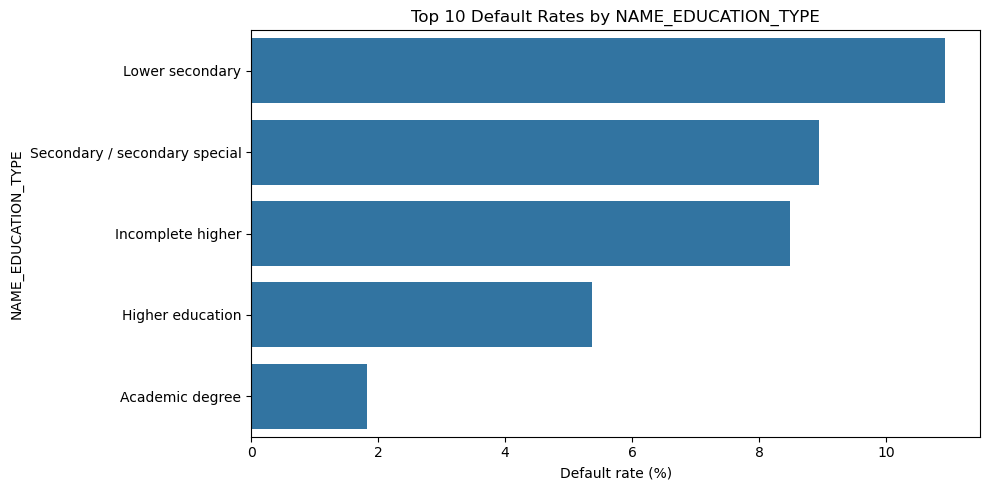


NAME_FAMILY_STATUS — highest default-rate categories:


,count,default_rate
NAME_FAMILY_STATUS,,
Civil marriage,29775,9.94
Single / not married,45444,9.81
Separated,19770,8.19
Married,196432,7.56
Widow,16088,5.82
Unknown,2,0.00


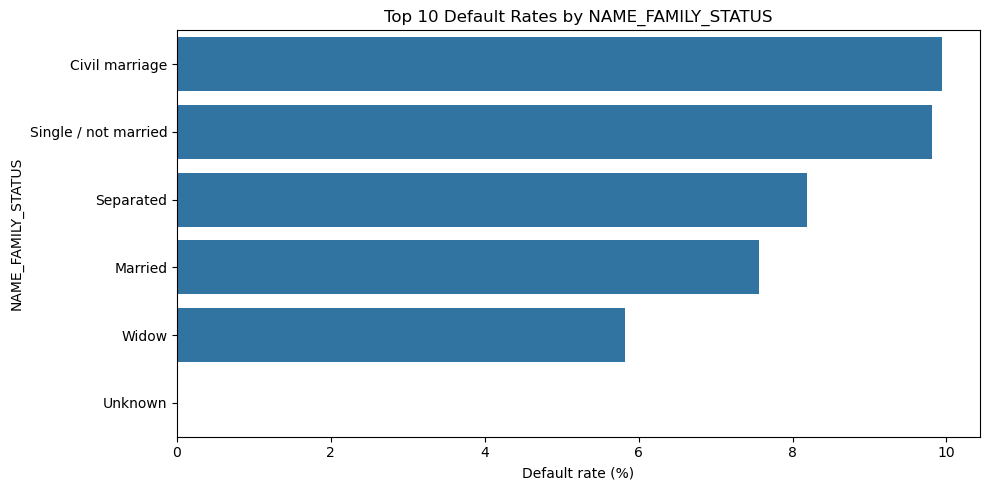


NAME_HOUSING_TYPE — highest default-rate categories:


,count,default_rate
NAME_HOUSING_TYPE,,
Rented apartment,4881,12.31
With parents,14840,11.70
Municipal apartment,11183,8.54
Co-op apartment,1122,7.93
House / apartment,272868,7.80
Office apartment,2617,6.57


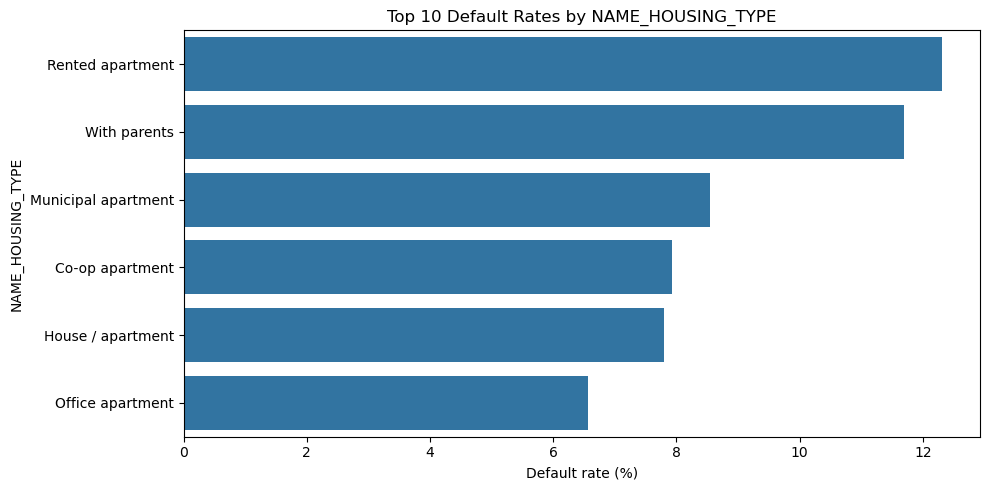


OCCUPATION_TYPE — highest default-rate categories:


,count,default_rate
OCCUPATION_TYPE,,
Low-skill Laborers,2093,17.15
Drivers,18603,11.33
Waiters/barmen staff,1348,11.28
Security staff,6721,10.74
Laborers,55186,10.58
Cooking staff,5946,10.44
Sales staff,32102,9.63
Cleaning staff,4653,9.61


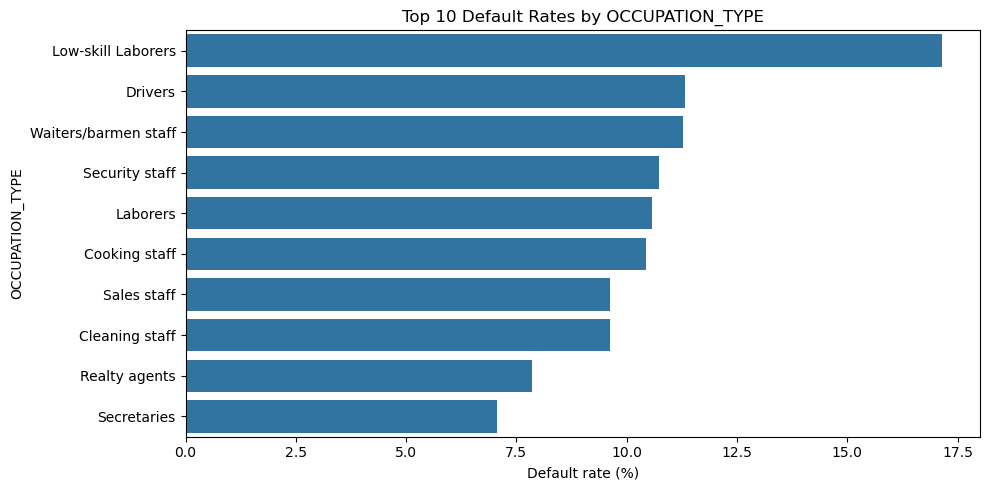

In [73]:
categorical_eda_cols = [
    c for c in [
        'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE',
        'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
        'OCCUPATION_TYPE'
    ] if c in application_train_clean.columns
]

for col in categorical_eda_cols:
    rate_table = (
        application_train_clean.groupby(col, dropna=False)['TARGET']
        .agg(['count', 'mean'])
        .rename(columns={'mean': 'default_rate'})
        .sort_values('default_rate', ascending=False)
    )
    rate_table['default_rate'] = (100 * rate_table['default_rate']).round(2)
    print(f'\n{col} — highest default-rate categories:')
    display(rate_table.head(8))

    plt.figure(figsize=(10, 5))
    plot_df = rate_table.sort_values('default_rate', ascending=False).head(10).reset_index()
    sns.barplot(data=plot_df, x='default_rate', y=col)
    plt.title(f'Top 10 Default Rates by {col}')
    plt.xlabel('Default rate (%)')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()



AMT_INCOME_TOTAL — distribution by target:


,count,median,mean
TARGET,,,
0,282686,148500.0,169077.72
1,24825,135000.0,165611.76


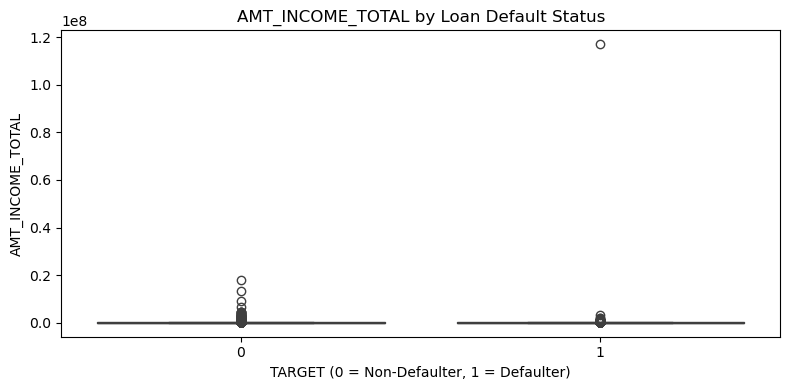


AMT_CREDIT — distribution by target:


,count,median,mean
TARGET,,,
0,282686,517788.0,602648.28
1,24825,497520.0,557778.53


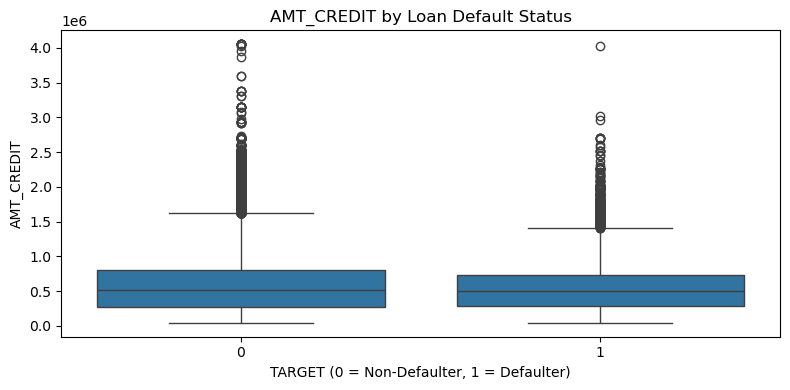


AMT_ANNUITY — distribution by target:


,count,median,mean
TARGET,,,
0,282686,24876.0,27163.53
1,24825,25263.0,26481.74


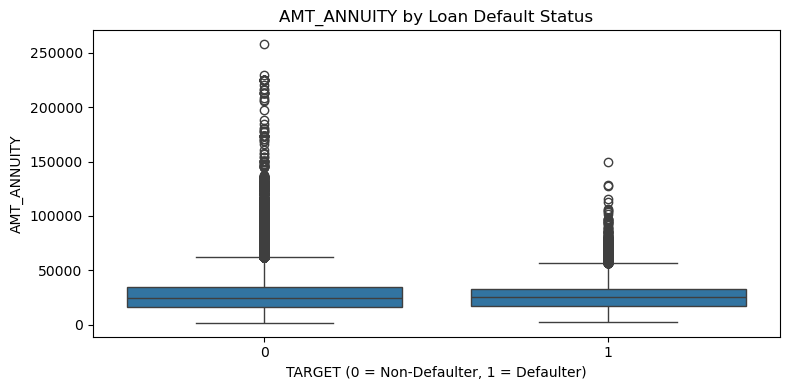


DAYS_BIRTH — distribution by target:


,count,median,mean
TARGET,,,
0,282686,-15877.0,-16138.18
1,24825,-14282.0,-14884.83


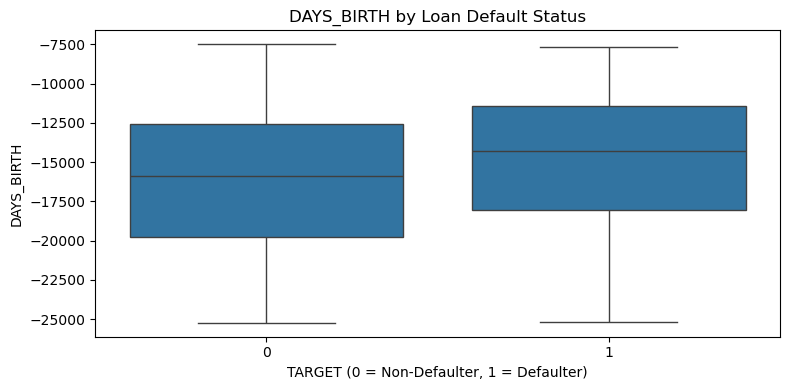


DAYS_EMPLOYED — distribution by target:


,count,median,mean
TARGET,,,
0,282686,-1648.0,-2291.72
1,24825,-1458.0,-1794.81


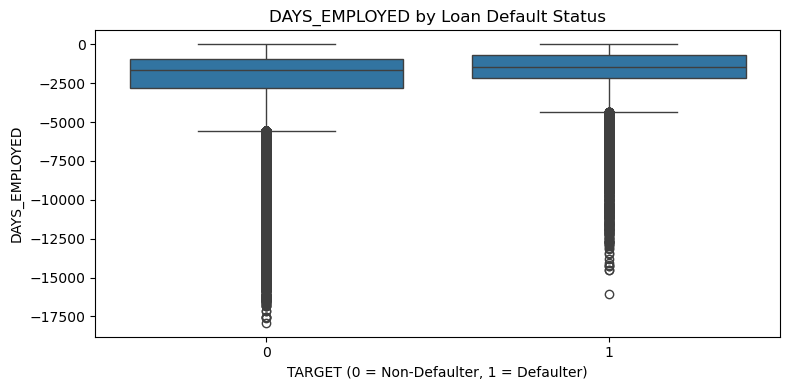


EXT_SOURCE_2 — distribution by target:


,count,median,mean
TARGET,,,
0,282686,0.57,0.52
1,24825,0.44,0.41


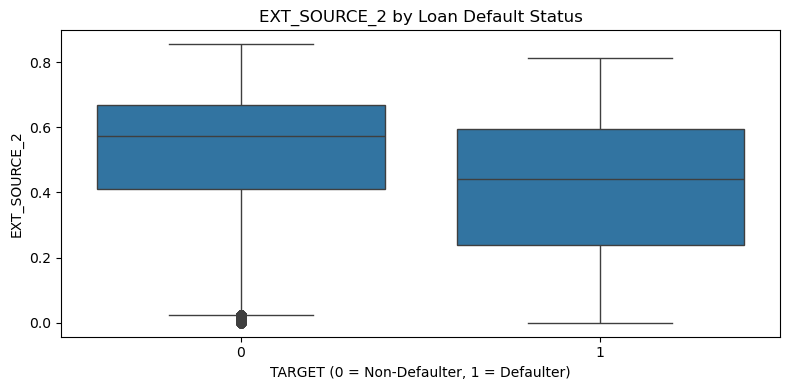


EXT_SOURCE_3 — distribution by target:


,count,median,mean
TARGET,,,
0,282686,0.54,0.52
1,24825,0.48,0.42


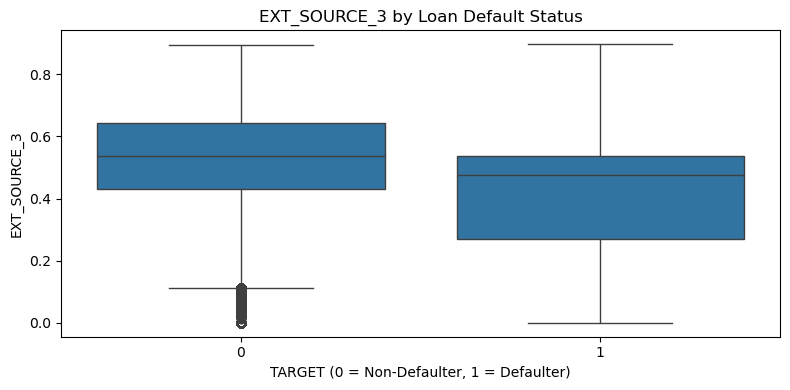

In [75]:

important_numeric = [
    c for c in [
        'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
        'DAYS_BIRTH', 'DAYS_EMPLOYED', 'EXT_SOURCE_2', 'EXT_SOURCE_3'
    ] if c in application_train_clean.columns
]

for col in important_numeric:
    summary = application_train_clean.groupby('TARGET')[col].agg(['count', 'median', 'mean']).round(2)
    print(f'\n{col} — distribution by target:')
    display(summary)

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=application_train_clean, x='TARGET', y=col)
    plt.title(f'{col} by Loan Default Status')
    plt.xlabel('TARGET (0 = Non-Defaulter, 1 = Defaulter)')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


Top 15 numerical features by absolute correlation with TARGET:


,correlation
EXT_SOURCE_2,-0.160295
EXT_SOURCE_3,-0.155892
DAYS_BIRTH,0.078239
DAYS_EMPLOYED,0.063368
REGION_RATING_CLIENT_W_CITY,0.060893
REGION_RATING_CLIENT,0.058899
DAYS_LAST_PHONE_CHANGE,0.055218
DAYS_ID_PUBLISH,0.051457
REG_CITY_NOT_WORK_CITY,0.050994
FLAG_EMP_PHONE,0.045982


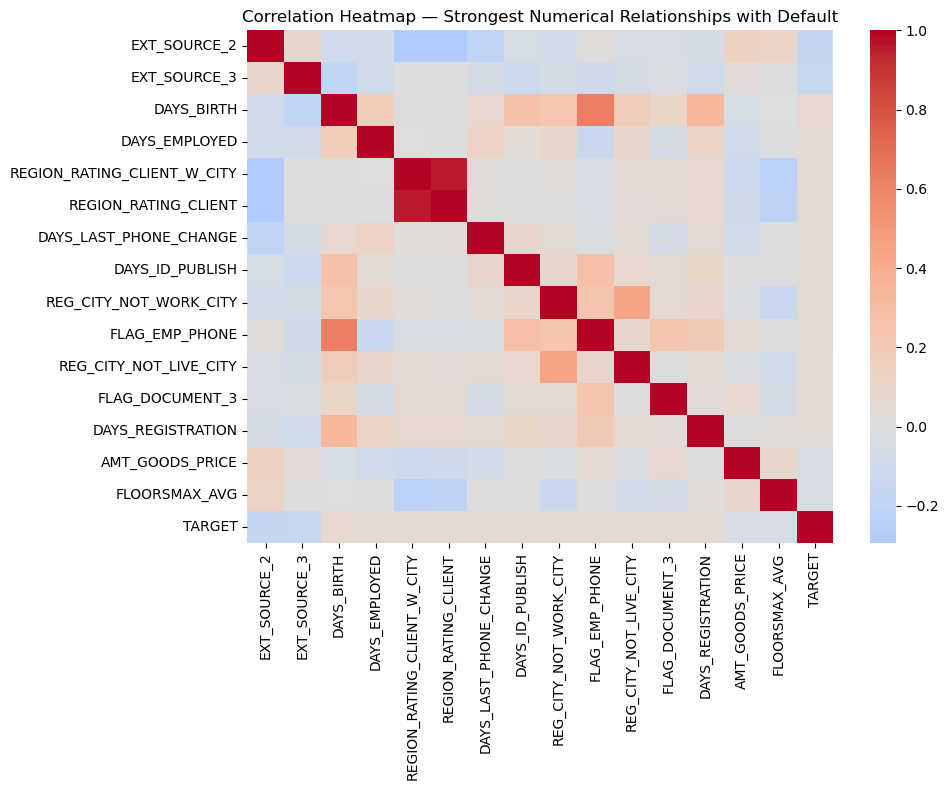

EDA observations:
- The target is imbalanced: 8.07% of applicants are defaulters.
- The strongest absolute numerical correlation with TARGET is EXT_SOURCE_2 (-0.160).


In [239]:

eda_numeric = application_train_clean.select_dtypes(include=np.number).copy()
correlations = eda_numeric.corr(numeric_only=True)['TARGET'].drop('TARGET').abs().sort_values(ascending=False)
top_corr_features = correlations.head(15).index.tolist()

print('Top 15 numerical features by absolute correlation with TARGET:')
display(eda_numeric[top_corr_features + ['TARGET']].corr()['TARGET'].drop('TARGET').sort_values(key=abs, ascending=False).to_frame('correlation'))

plt.figure(figsize=(10, 8))
sns.heatmap(eda_numeric[top_corr_features + ['TARGET']].corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Strongest Numerical Relationships with Default')
plt.tight_layout()
plt.show()
print('EDA observations:')
print(f'- The target is imbalanced: {100 * application_train_clean.TARGET.mean():.2f}% of applicants are defaulters.')
if top_corr_features:
    strongest = correlations.index[0]
    print(f'- The strongest absolute numerical correlation with TARGET is {strongest} ({eda_numeric[strongest].corr(eda_numeric.TARGET):.3f}).')


In [79]:
clean_datasets = {
    'application_train': application_train_clean,
    'bureau': bureau_clean,
    'bureau_balance': bureau_balance_clean,
    'POS_CASH_balance': pos_cash_balance_clean,
    'credit_card_balance': credit_card_balance_clean,
    'previous_application': previous_application_clean,
    'installments_payments': installments_payments_clean
}

In [81]:
bureau_clean.select_dtypes(include=np.number).columns.tolist()

['SK_ID_CURR',
 'SK_ID_BUREAU',
 'DAYS_CREDIT',
 'CREDIT_DAY_OVERDUE',
 'DAYS_CREDIT_ENDDATE',
 'DAYS_ENDDATE_FACT',
 'AMT_CREDIT_MAX_OVERDUE',
 'CNT_CREDIT_PROLONG',
 'AMT_CREDIT_SUM',
 'AMT_CREDIT_SUM_DEBT',
 'AMT_CREDIT_SUM_LIMIT',
 'AMT_CREDIT_SUM_OVERDUE',
 'DAYS_CREDIT_UPDATE',
 'AMT_ANNUITY']

In [83]:
bureau_agg = bureau_clean.groupby('SK_ID_CURR').agg({
    'SK_ID_BUREAU': 'count',
    'DAYS_CREDIT': ['mean', 'min', 'max'],
    'CREDIT_DAY_OVERDUE': ['mean', 'max'],
    'AMT_CREDIT_SUM': ['mean', 'max', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['mean', 'max', 'sum'],
    'AMT_CREDIT_SUM_OVERDUE': ['mean', 'max', 'sum'],
    'CNT_CREDIT_PROLONG': ['mean', 'max'],
    'DAYS_CREDIT_ENDDATE': ['mean', 'min', 'max'],
    'DAYS_ENDDATE_FACT': ['mean', 'min', 'max']
})

In [85]:
bureau_agg.columns = [
    'BUREAU_' + '_'.join(col).upper()
    for col in bureau_agg.columns
]

In [87]:
bureau_agg.head()

,BUREAU_SK_ID_BUREAU_COUNT,BUREAU_DAYS_CREDIT_MEAN,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_MAX,BUREAU_CREDIT_DAY_OVERDUE_MEAN,BUREAU_CREDIT_DAY_OVERDUE_MAX,BUREAU_AMT_CREDIT_SUM_MEAN,BUREAU_AMT_CREDIT_SUM_MAX,BUREAU_AMT_CREDIT_SUM_SUM,BUREAU_AMT_CREDIT_SUM_DEBT_MEAN,...,BUREAU_AMT_CREDIT_SUM_OVERDUE_MAX,BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM,BUREAU_CNT_CREDIT_PROLONG_MEAN,BUREAU_CNT_CREDIT_PROLONG_MAX,BUREAU_DAYS_CREDIT_ENDDATE_MEAN,BUREAU_DAYS_CREDIT_ENDDATE_MIN,BUREAU_DAYS_CREDIT_ENDDATE_MAX,BUREAU_DAYS_ENDDATE_FACT_MEAN,BUREAU_DAYS_ENDDATE_FACT_MIN,BUREAU_DAYS_ENDDATE_FACT_MAX
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,7,-735.000000,-1572,-49,0.0,0,207623.571429,378000.0,1453365.000,85240.928571,...,0.0,0.0,0.0,0,82.428571,-1329.0,1778.0,-856.142857,-1328.0,-544.0
100002,8,-874.000000,-1437,-103,0.0,0,108131.945625,450000.0,865055.565,30722.625000,...,0.0,0.0,0.0,0,-344.250000,-1072.0,780.0,-747.375000,-1185.0,-36.0
100003,4,-1400.750000,-2586,-606,0.0,0,254350.125000,810000.0,1017400.500,0.000000,...,0.0,0.0,0.0,0,-544.500000,-2434.0,1216.0,-1047.250000,-2131.0,-540.0
100004,2,-867.000000,-1326,-408,0.0,0,94518.900000,94537.8,189037.800,0.000000,...,0.0,0.0,0.0,0,-488.500000,-595.0,-382.0,-532.500000,-683.0,-382.0
100005,3,-190.666667,-373,-62,0.0,0,219042.000000,568800.0,657126.000,189469.500000,...,0.0,0.0,0.0,0,439.333333,-128.0,1324.0,-639.000000,-897.0,-123.0


In [89]:
print("Original bureau shape:", bureau_clean.shape)
print("Aggregated bureau shape:", bureau_agg.shape)

Original bureau shape: (1716428, 17)
Aggregated bureau shape: (305811, 23)


In [91]:
bureau_balance_clean.columns.tolist()

['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']

In [93]:
bureau_balance_agg = bureau_balance_clean.groupby('SK_ID_BUREAU').agg({
    'MONTHS_BALANCE': ['min', 'max', 'count'],
    'STATUS': 'nunique'
})

In [94]:
bureau_balance_agg.head()

MONTHS_BALANCE            STATUS
                        min max count nunique
SK_ID_BUREAU                                 
5001709                 -96   0    97       2
5001710                 -82   0    83       3
5001711                  -3   0     4       2
5001712                 -18   0    19       2
5001713                 -21   0    22       1

In [97]:
bureau_id_mapping = bureau_clean[
    ['SK_ID_BUREAU', 'SK_ID_CURR']
].drop_duplicates()

In [98]:
bureau_balance_agg = bureau_balance_clean.groupby('SK_ID_BUREAU').agg({
    'MONTHS_BALANCE': ['min', 'max', 'count'],
    'STATUS': 'nunique'
})

In [100]:
bureau_balance_agg.columns = [
    'BB_MONTHS_BALANCE_MIN',
    'BB_MONTHS_BALANCE_MAX',
    'BB_MONTHS_BALANCE_COUNT',
    'BB_STATUS_NUNIQUE'
]
bureau_balance_agg = bureau_balance_agg.reset_index()

In [101]:
print(bureau_balance_agg.columns)

Index(['SK_ID_BUREAU', 'BB_MONTHS_BALANCE_MIN', 'BB_MONTHS_BALANCE_MAX',
       'BB_MONTHS_BALANCE_COUNT', 'BB_STATUS_NUNIQUE'],
      dtype='object')


In [105]:
bureau_id_mapping = bureau_clean[
    ['SK_ID_BUREAU', 'SK_ID_CURR']
].drop_duplicates()

In [107]:
bureau_balance_with_customer = bureau_balance_agg.merge(
    bureau_id_mapping,
    on='SK_ID_BUREAU',
    how='left'
)

In [109]:
bureau_balance_with_customer.head()

,SK_ID_BUREAU,BB_MONTHS_BALANCE_MIN,BB_MONTHS_BALANCE_MAX,BB_MONTHS_BALANCE_COUNT,BB_STATUS_NUNIQUE,SK_ID_CURR
0,5001709,-96,0,97,2,NaN
1,5001710,-82,0,83,3,162368.0
2,5001711,-3,0,4,2,162368.0
3,5001712,-18,0,19,2,162368.0
4,5001713,-21,0,22,1,150635.0


In [111]:
bureau_balance_customer_agg = (
    bureau_balance_with_customer
    .groupby('SK_ID_CURR')
    .agg({
        'BB_MONTHS_BALANCE_MIN': 'min',
        'BB_MONTHS_BALANCE_MAX': 'max',
        'BB_MONTHS_BALANCE_COUNT': 'sum',
        'BB_STATUS_NUNIQUE': 'mean'
    })
)

In [113]:
print(bureau_balance_customer_agg.shape)

(134542, 4)


In [115]:
previous_application_agg = previous_application_clean.groupby('SK_ID_CURR').agg({
    'SK_ID_PREV': 'count',
    'AMT_ANNUITY': ['mean', 'max'],
    'AMT_APPLICATION': ['mean', 'max', 'sum'],
    'AMT_CREDIT': ['mean', 'max', 'sum'],
    'AMT_DOWN_PAYMENT': ['mean', 'sum'],
    'AMT_GOODS_PRICE': ['mean', 'max'],
    'RATE_DOWN_PAYMENT': 'mean',
    'DAYS_DECISION': ['mean', 'min', 'max'],
    'CNT_PAYMENT': ['mean', 'max']
})

In [116]:
previous_application_agg.columns = [
    'PREV_' + '_'.join(col).upper()
    for col in previous_application_agg.columns
]
previous_application_agg = previous_application_agg.reset_index()

In [117]:
print("Original shape:", previous_application_clean.shape)
print("Aggregated shape:", previous_application_agg.shape)

Original shape: (1670214, 35)
Aggregated shape: (338857, 20)


In [121]:
pos_cash_agg = pos_cash_balance_clean.groupby('SK_ID_PREV').agg({
    'MONTHS_BALANCE': ['min', 'max', 'count'],
    'CNT_INSTALMENT': ['mean', 'max'],
    'CNT_INSTALMENT_FUTURE': ['mean', 'min'],
    'SK_DPD': ['mean', 'max', 'sum'],
    'SK_DPD_DEF': ['mean', 'max', 'sum']
})
pos_cash_agg.columns = [
    'POS_' + '_'.join(col).upper()
    for col in pos_cash_agg.columns
]
pos_cash_agg = pos_cash_agg.reset_index()
print("Aggregated POS-CASH by previous loan:", pos_cash_agg.shape)
print(pos_cash_agg.head())

Aggregated POS-CASH by previous loan: (936325, 14)
   SK_ID_PREV  POS_MONTHS_BALANCE_MIN  POS_MONTHS_BALANCE_MAX  \
0     1000001                     -10                      -8   
1     1000002                     -54                     -50   
2     1000003                      -4                      -1   
3     1000004                     -29                     -22   
4     1000005                     -56                     -46   

   POS_MONTHS_BALANCE_COUNT  POS_CNT_INSTALMENT_MEAN  POS_CNT_INSTALMENT_MAX  \
0                         3                 8.666667                    12.0   
1                         5                 5.200000                     6.0   
2                         4                12.000000                    12.0   
3                         8                 9.625000                    10.0   
4                        11                10.000000                    10.0   

   POS_CNT_INSTALMENT_FUTURE_MEAN  POS_CNT_INSTALMENT_FUTURE_MIN  \
0        

In [123]:
pos_prev_mapping = previous_application_clean[
    ['SK_ID_PREV', 'SK_ID_CURR']
].drop_duplicates()
pos_cash_with_customer = pos_cash_agg.merge(
    pos_prev_mapping,
    on='SK_ID_PREV',
    how='left'
)
print("After mapping to customers:", pos_cash_with_customer.shape)

After mapping to customers: (936325, 15)


In [125]:
pos_cash_customer_agg = (
    pos_cash_with_customer
    .groupby('SK_ID_CURR')
    .agg({
        'POS_MONTHS_BALANCE_MIN': 'min',
        'POS_MONTHS_BALANCE_MAX': 'max',
        'POS_MONTHS_BALANCE_COUNT': 'sum',
        'POS_CNT_INSTALMENT_MEAN': 'mean',
        'POS_CNT_INSTALMENT_MAX': 'max',
        'POS_CNT_INSTALMENT_FUTURE_MEAN': 'mean',
        'POS_CNT_INSTALMENT_FUTURE_MIN': 'min',
        'POS_SK_DPD_MEAN': 'mean',
        'POS_SK_DPD_MAX': 'max',
        'POS_SK_DPD_SUM': 'sum',
        'POS_SK_DPD_DEF_MEAN': 'mean',
        'POS_SK_DPD_DEF_MAX': 'max',
        'POS_SK_DPD_DEF_SUM': 'sum'
    })
    .reset_index()
)
print("Customer-level POS-CASH shape:", pos_cash_customer_agg.shape)
print(pos_cash_customer_agg.head())

Customer-level POS-CASH shape: (334359, 14)
   SK_ID_CURR  POS_MONTHS_BALANCE_MIN  POS_MONTHS_BALANCE_MAX  \
0    100001.0                     -57                     -53   
1    100002.0                     -19                      -1   
2    100003.0                     -77                     -18   
3    100004.0                     -27                     -24   
4    100005.0                     -25                     -15   

   POS_MONTHS_BALANCE_COUNT  POS_CNT_INSTALMENT_MEAN  POS_CNT_INSTALMENT_MAX  \
0                         5                 4.000000                     4.0   
1                        19                24.000000                    24.0   
2                        28                 9.791667                    12.0   
3                         4                 3.750000                     4.0   
4                        11                11.727273                    12.0   

   POS_CNT_INSTALMENT_FUTURE_MEAN  POS_CNT_INSTALMENT_FUTURE_MIN  \
0               

In [127]:
credit_card_agg = credit_card_balance_clean.groupby('SK_ID_PREV').agg({
    'MONTHS_BALANCE': ['min', 'max', 'count'],
    'AMT_BALANCE': ['mean', 'max'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean', 'max'],
    'AMT_DRAWINGS_CURRENT': ['mean', 'sum'],
    'CNT_DRAWINGS_CURRENT': ['mean', 'sum'],
    'AMT_PAYMENT_TOTAL_CURRENT': ['mean', 'sum'],
    'AMT_PAYMENT_CURRENT': ['mean', 'sum'],
    'SK_DPD': ['mean', 'max', 'sum'],
    'SK_DPD_DEF': ['mean', 'max', 'sum']
})
credit_card_agg.columns = [
    'CC_' + '_'.join(col).upper()
    for col in credit_card_agg.columns
]
credit_card_agg = credit_card_agg.reset_index()
print("Aggregated credit-card by previous loan:", credit_card_agg.shape)

Aggregated credit-card by previous loan: (104307, 22)


In [129]:
cc_prev_mapping = previous_application_clean[
    ['SK_ID_PREV', 'SK_ID_CURR']
].drop_duplicates()
credit_card_with_customer = credit_card_agg.merge(
    cc_prev_mapping,
    on='SK_ID_PREV',
    how='left'
)
print("After mapping to customers:", credit_card_with_customer.shape)

After mapping to customers: (104307, 23)


In [130]:
credit_card_customer_agg = (
    credit_card_with_customer
    .groupby('SK_ID_CURR')
    .agg({
        'CC_MONTHS_BALANCE_MIN': 'min',
        'CC_MONTHS_BALANCE_MAX': 'max',
        'CC_MONTHS_BALANCE_COUNT': 'sum',
        'CC_AMT_BALANCE_MEAN': 'mean',
        'CC_AMT_BALANCE_MAX': 'max',
        'CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN': 'mean',
        'CC_AMT_CREDIT_LIMIT_ACTUAL_MAX': 'max',
        'CC_AMT_DRAWINGS_CURRENT_MEAN': 'mean',
        'CC_AMT_DRAWINGS_CURRENT_SUM': 'sum',
        'CC_CNT_DRAWINGS_CURRENT_MEAN': 'mean',
        'CC_CNT_DRAWINGS_CURRENT_SUM': 'sum',
        'CC_AMT_PAYMENT_TOTAL_CURRENT_MEAN': 'mean',
        'CC_AMT_PAYMENT_TOTAL_CURRENT_SUM': 'sum',
        'CC_AMT_PAYMENT_CURRENT_MEAN': 'mean',
        'CC_AMT_PAYMENT_CURRENT_SUM': 'sum',
        'CC_SK_DPD_MEAN': 'mean',
        'CC_SK_DPD_MAX': 'max',
        'CC_SK_DPD_SUM': 'sum',
        'CC_SK_DPD_DEF_MEAN': 'mean',
        'CC_SK_DPD_DEF_MAX': 'max',
        'CC_SK_DPD_DEF_SUM': 'sum'
    })
    .reset_index()
)
print("Customer-level credit-card shape:", credit_card_customer_agg.shape)
print(credit_card_customer_agg.head())

Customer-level credit-card shape: (92447, 22)
   SK_ID_CURR  CC_MONTHS_BALANCE_MIN  CC_MONTHS_BALANCE_MAX  \
0    100006.0                     -6                     -1   
1    100011.0                    -75                     -2   
2    100021.0                    -18                     -2   
3    100023.0                    -11                     -4   
4    100028.0                    -49                     -1   

   CC_MONTHS_BALANCE_COUNT  CC_AMT_BALANCE_MEAN  CC_AMT_BALANCE_MAX  \
0                        6             0.000000               0.000   
1                       74         54482.111149          189000.000   
2                       17             0.000000               0.000   
3                        8             0.000000               0.000   
4                       49          8085.058163           37335.915   

   CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN  CC_AMT_CREDIT_LIMIT_ACTUAL_MAX  \
0                    270000.000000                          270000   
1       

In [133]:
installments_agg = installments_payments_clean.groupby('SK_ID_PREV').agg({
    'NUM_INSTALMENT_VERSION': ['mean', 'max'],
    'NUM_INSTALMENT_NUMBER': ['max'],
    'DAYS_INSTALMENT': ['mean', 'min', 'max'],
    'DAYS_ENTRY_PAYMENT': ['mean', 'min', 'max'],
    'AMT_INSTALMENT': ['mean', 'sum'],
    'AMT_PAYMENT': ['mean', 'sum']
})
installments_agg.columns = [
    'INST_' + '_'.join(col).upper()
    for col in installments_agg.columns
]
installments_agg = installments_agg.reset_index()
print("Aggregated installments by previous loan:", installments_agg.shape)

Aggregated installments by previous loan: (997752, 14)


In [134]:
inst_prev_mapping = previous_application_clean[
    ['SK_ID_PREV', 'SK_ID_CURR']
].drop_duplicates()
installments_with_customer = installments_agg.merge(
    inst_prev_mapping,
    on='SK_ID_PREV',
    how='left'
)
print("After mapping to customers:", installments_with_customer.shape)

After mapping to customers: (997752, 15)


In [137]:
installments_customer_agg = (
    installments_with_customer
    .groupby('SK_ID_CURR')
    .agg({
        'INST_NUM_INSTALMENT_VERSION_MEAN': 'mean',
        'INST_NUM_INSTALMENT_VERSION_MAX': 'max',
        'INST_NUM_INSTALMENT_NUMBER_MAX': 'max',
        'INST_DAYS_INSTALMENT_MEAN': 'mean',
        'INST_DAYS_INSTALMENT_MIN': 'min',
        'INST_DAYS_INSTALMENT_MAX': 'max',
        'INST_DAYS_ENTRY_PAYMENT_MEAN': 'mean',
        'INST_DAYS_ENTRY_PAYMENT_MIN': 'min',
        'INST_DAYS_ENTRY_PAYMENT_MAX': 'max',
        'INST_AMT_INSTALMENT_MEAN': 'mean',
        'INST_AMT_INSTALMENT_SUM': 'sum',
        'INST_AMT_PAYMENT_MEAN': 'mean',
        'INST_AMT_PAYMENT_SUM': 'sum'
    })
    .reset_index()
)
print("Customer-level installments shape:", installments_customer_agg.shape)
print(installments_customer_agg.head())

Customer-level installments shape: (336935, 14)
   SK_ID_CURR  INST_NUM_INSTALMENT_VERSION_MEAN  \
0    100001.0                          1.250000   
1    100002.0                          1.052632   
2    100003.0                          1.047619   
3    100004.0                          1.333333   
4    100005.0                          1.111111   

   INST_NUM_INSTALMENT_VERSION_MAX  INST_NUM_INSTALMENT_NUMBER_MAX  \
0                              2.0                               4   
1                              2.0                              19   
2                              2.0                              12   
3                              2.0                               3   
4                              2.0                               9   

   INST_DAYS_INSTALMENT_MEAN  INST_DAYS_INSTALMENT_MIN  \
0               -1664.000000                   -1709.0   
1                -295.000000                    -565.0   
2               -1164.333333                   -23

In [139]:
final_df = application_train_clean.copy()
final_df = final_df.merge(
    bureau_agg,
    on='SK_ID_CURR',
    how='left'
)
final_df = final_df.merge(
    bureau_balance_customer_agg.reset_index(),
    on='SK_ID_CURR',
    how='left'
)
final_df = final_df.merge(
    previous_application_agg,
    on='SK_ID_CURR',
    how='left'
)
final_df = final_df.merge(
    pos_cash_customer_agg,
    on='SK_ID_CURR',
    how='left'
)
final_df = final_df.merge(
    credit_card_customer_agg,
    on='SK_ID_CURR',
    how='left'
)
final_df = final_df.merge(
    installments_customer_agg,
    on='SK_ID_CURR',
    how='left'
)
print("Final dataset shape:", final_df.shape)

Final dataset shape: (307511, 174)


In [141]:
print("Duplicate rows:", final_df.duplicated().sum())
print("Duplicate SK_ID_CURR:", final_df['SK_ID_CURR'].duplicated().sum())

Duplicate rows: 0
Duplicate SK_ID_CURR: 0


In [143]:
missing_count = final_df.isnull().sum().sum()
print("Total missing values:", missing_count)

Total missing values: 7509760


In [145]:
print(final_df['TARGET'].value_counts())

TARGET
0    282686
1     24825
Name: count, dtype: int64


In [147]:
print(final_df.dtypes.value_counts())

float64    121
int64       40
object      13
Name: count, dtype: int64


In [149]:
numeric_cols = final_df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    if col != 'TARGET':
        final_df[col] = final_df[col].fillna(0)

In [150]:
categorical_cols = final_df.select_dtypes(include='object').columns
for col in categorical_cols:
    final_df[col] = final_df[col].fillna('Unknown')

In [153]:
print("Total missing values:", final_df.isnull().sum().sum())

Total missing values: 0


In [155]:
print("Final dataset shape:", final_df.shape)
print("Target distribution:")
print(final_df['TARGET'].value_counts())

Final dataset shape: (307511, 174)
Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64


# Modeling Strategy — Leakage-Safe and Cross-Validated

The final merged dataset contains one row per applicant. From this point onward, **the test set is isolated before any model-specific imputation, encoding, scaling or feature-selection decision**. This is the key safeguard against data leakage.

We compare three complementary approaches:
1. **Regularized Logistic Regression** — interpretable linear baseline.
2. **Random Forest** — nonlinear ensemble with class weighting.
3. **XGBoost** — gradient boosting model with class-imbalance weighting.

Hyperparameters are selected with stratified 3-fold cross-validation on a training-only tuning sample. The selected models are then refit on all training data.


In [158]:
model_df = final_df.copy()
print('Final modeling dataset:', model_df.shape)
print('Missing values before model pipeline:', int(model_df.isnull().sum().sum()))
print('Duplicate applicant IDs:', int(model_df['SK_ID_CURR'].duplicated().sum()))
print('Target distribution (%):')
print((100 * model_df['TARGET'].value_counts(normalize=True)).round(2))


Final modeling dataset: (307511, 174)
Missing values before model pipeline: 0
Duplicate applicant IDs: 0
Target distribution (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [160]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, precision_recall_curve, roc_curve
)
from sklearn.base import clone
import xgboost as xgb

RANDOM_STATE = 42

X_raw = model_df.drop(columns=['TARGET', 'SK_ID_CURR'])
y = model_df['TARGET'].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print('Train shape:', X_train_raw.shape)
print('Test shape :', X_test_raw.shape)
print('Train default rate:', round(100 * y_train.mean(), 2), '%')
print('Test default rate :', round(100 * y_test.mean(), 2), '%')


Train shape: (246008, 172)
Test shape : (61503, 172)
Train default rate: 8.07 %
Test default rate : 8.07 %


In [162]:

train_numeric = X_train_raw.select_dtypes(include=np.number).copy()
train_numeric = train_numeric.fillna(train_numeric.median())

corr_matrix = train_numeric.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
correlated_to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]

selected_features = [c for c in X_train_raw.columns if c not in correlated_to_drop]
X_train_sel = X_train_raw[selected_features].copy()
X_test_sel = X_test_raw[selected_features].copy()

print(f'Original predictors : {X_train_raw.shape[1]}')
print(f'Redundant predictors removed at |r| > 0.95: {len(correlated_to_drop)}')
print(f'Selected predictors : {len(selected_features)}')
if correlated_to_drop:
    print('Examples:', correlated_to_drop[:15])


Original predictors : 172
Redundant predictors removed at |r| > 0.95: 27
Selected predictors : 145
Examples: ['AMT_GOODS_PRICE', 'REGION_RATING_CLIENT_W_CITY', 'YEARS_BEGINEXPLUATATION_MODE', 'FLOORSMAX_MODE', 'YEARS_BEGINEXPLUATATION_MEDI', 'FLOORSMAX_MEDI', 'OBS_60_CNT_SOCIAL_CIRCLE', 'BUREAU_AMT_CREDIT_SUM_DEBT_SUM', 'BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM', 'PREV_AMT_CREDIT_MEAN', 'PREV_AMT_CREDIT_MAX', 'PREV_AMT_CREDIT_SUM', 'PREV_AMT_GOODS_PRICE_MEAN', 'PREV_AMT_GOODS_PRICE_MAX', 'POS_CNT_INSTALMENT_FUTURE_MEAN']


In [186]:
numeric_features = X_train_sel.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train_sel.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
        ]), categorical_features)
    ],
    remainder='drop'
)

preprocessor_linear = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
        ]), categorical_features)
    ],
    remainder='drop'
)

print('Numeric features   :', len(numeric_features))
print('Categorical features:', len(categorical_features))


Numeric features   : 132
Categorical features: 13


In [188]:

tune_size = min(60000, len(X_train_sel))
X_tune, _, y_tune, _ = train_test_split(
    X_train_sel, y_train, train_size=tune_size, random_state=RANDOM_STATE, stratify=y_train
)
print('Tuning sample:', X_tune.shape)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()
print('Training scale_pos_weight:', round(positive_weight, 2))


Tuning sample: (60000, 145)
Training scale_pos_weight: 11.39


In [190]:

logistic_pipe = Pipeline([
    ('prep', preprocessor_linear),
    ('model', LogisticRegression(
        class_weight='balanced', solver='liblinear', max_iter=1500, random_state=RANDOM_STATE
    ))
])

logistic_search = RandomizedSearchCV(
    logistic_pipe,
    param_distributions={'model__C': np.logspace(-3, 1, 8)},
    n_iter=5, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
    verbose=1, refit=True
)
logistic_search.fit(X_tune, y_tune)
print('Best Logistic parameters:', logistic_search.best_params_)
print('Best 3-fold CV ROC-AUC:', round(logistic_search.best_score_, 4))


Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Logistic parameters: {'model__C': 0.003727593720314938}
Best 3-fold CV ROC-AUC: 0.7546


In [192]:

rf_pipe = Pipeline([
    ('prep', preprocessor_tree),
    ('model', RandomForestClassifier(
        class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1
    ))
])

rf_search = RandomizedSearchCV(
    rf_pipe,
    param_distributions={
        'model__n_estimators': [200, 300, 400],
        'model__max_depth': [8, 12, 16, None],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [2, 5, 10],
        'model__max_features': ['sqrt', 0.5]
    },
    n_iter=5, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
    verbose=1, refit=True
)
rf_search.fit(X_tune, y_tune)
print('Best Random Forest parameters:', rf_search.best_params_)
print('Best 3-fold CV ROC-AUC:', round(rf_search.best_score_, 4))


Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Random Forest parameters: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': None}
Best 3-fold CV ROC-AUC: 0.7411


In [198]:

xgb_pipe = Pipeline([
    ('prep', preprocessor_tree),
    ('model', xgb.XGBClassifier(
        objective='binary:logistic', eval_metric='auc', tree_method='hist',
        scale_pos_weight=positive_weight, random_state=RANDOM_STATE, n_jobs=-1
    ))
])

xgb_search = RandomizedSearchCV(
    xgb_pipe,
    param_distributions={
        'model__n_estimators': [200, 300, 400],
        'model__max_depth': [3, 5, 7],
        'model__learning_rate': [0.03, 0.05, 0.10],
        'model__min_child_weight': [1, 5, 10],
        'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0]
    },
    n_iter=6, scoring='roc_auc', cv=cv, random_state=RANDOM_STATE, n_jobs=-1,
    verbose=1, refit=True
)
xgb_search.fit(X_tune, y_tune)
print('Best XGBoost parameters:', xgb_search.best_params_)
print('Best 3-fold CV ROC-AUC:', round(xgb_search.best_score_, 4))


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best XGBoost parameters: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}
Best 3-fold CV ROC-AUC: 0.7548


In [200]:

logistic_model = clone(logistic_search.best_estimator_)
rf_model = clone(rf_search.best_estimator_)
xgb_model = clone(xgb_search.best_estimator_)

logistic_model.fit(X_train_sel, y_train)
rf_model.fit(X_train_sel, y_train)
xgb_model.fit(X_train_sel, y_train)

models = {
    'Regularized Logistic Regression': logistic_model,
    'Tuned Random Forest': rf_model,
    'Tuned XGBoost': xgb_model
}
print('All selected models refit on the complete training set.')


All selected models refit on the complete training set.


In [202]:
def evaluate_model(name, model, X_eval, y_eval, threshold=0.50):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_eval, pred),
        'Balanced_Accuracy': balanced_accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred, zero_division=0),
        'Recall': recall_score(y_eval, pred, zero_division=0),
        'F1': f1_score(y_eval, pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_eval, proba),
        'PR_AUC': average_precision_score(y_eval, proba)
    }, proba, pred

results = []
predictions = {}
for name, model in models.items():
    metrics, proba, pred = evaluate_model(name, model, X_test_sel, y_test, threshold=0.50)
    results.append(metrics)
    predictions[name] = {'proba': proba, 'pred': pred}

results_df = pd.DataFrame(results).sort_values(['ROC_AUC', 'PR_AUC', 'F1'], ascending=False)
display(results_df.round(4))


,Model,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,Tuned XGBoost,0.5,0.7118,0.7032,0.1752,0.6928,0.2796,0.7706,0.2677
0,Regularized Logistic Regression,0.5,0.6987,0.6950,0.1679,0.6906,0.2701,0.7614,0.2455
1,Tuned Random Forest,0.5,0.9188,0.5213,0.4700,0.0473,0.0860,0.7582,0.2409


In [204]:

for name in models:
    pred = predictions[name]['pred']
    print('\n' + '=' * 80)
    print(name)
    print('=' * 80)
    print('Confusion Matrix:\n', confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=4, zero_division=0))



Regularized Logistic Regression
Confusion Matrix:
 [[39543 16995]
 [ 1536  3429]]
              precision    recall  f1-score   support

           0     0.9626    0.6994    0.8102     56538
           1     0.1679    0.6906    0.2701      4965

    accuracy                         0.6987     61503
   macro avg     0.5652    0.6950    0.5401     61503
weighted avg     0.8985    0.6987    0.7666     61503


Tuned Random Forest
Confusion Matrix:
 [[56273   265]
 [ 4730   235]]
              precision    recall  f1-score   support

           0     0.9225    0.9953    0.9575     56538
           1     0.4700    0.0473    0.0860      4965

    accuracy                         0.9188     61503
   macro avg     0.6962    0.5213    0.5218     61503
weighted avg     0.8859    0.9188    0.8871     61503


Tuned XGBoost
Confusion Matrix:
 [[40338 16200]
 [ 1525  3440]]
              precision    recall  f1-score   support

           0     0.9636    0.7135    0.8199     56538
           1     0

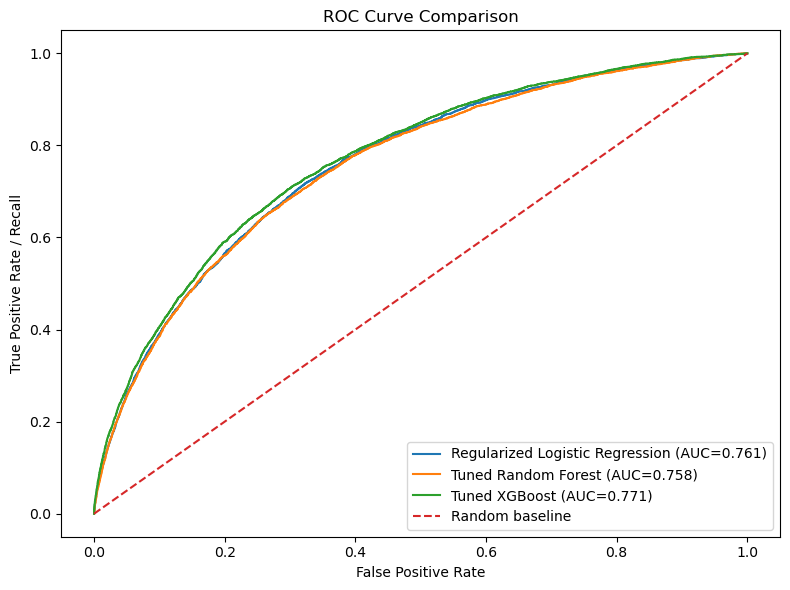

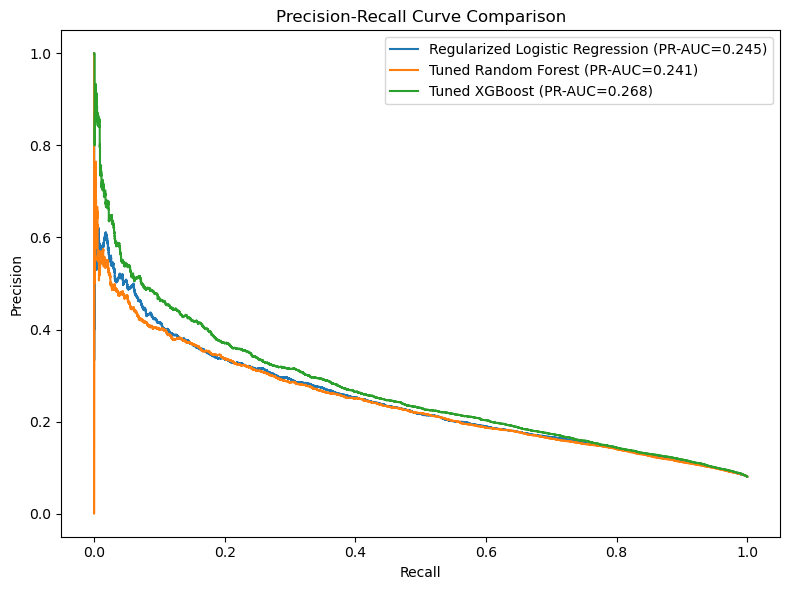

In [206]:

plt.figure(figsize=(8, 6))
for name in models:
    proba = predictions[name]['proba']
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate / Recall')
plt.title('ROC Curve Comparison')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name in models:
    proba = predictions[name]['proba']
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(recall, precision, label=f'{name} (PR-AUC={ap:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.tight_layout()
plt.show()


## Model Selection Rationale

For an imbalanced default-prediction problem, a high accuracy score can be misleading. The preferred model is selected primarily using **ROC-AUC and PR-AUC**, with **F1 and recall** used as additional minority-class checks. This makes the decision evidence-based rather than choosing a model simply because it has the highest accuracy.


In [231]:

best_row = results_df.iloc[0]
best_model_name = best_row['Model']
best_model = models[best_model_name]
print('Selected model:', best_model_name)
print('ROC-AUC:', round(best_row['ROC_AUC'], 4))
print('PR-AUC :', round(best_row['PR_AUC'], 4))
print('F1     :', round(best_row['F1'], 4))
print('Recall :', round(best_row['Recall'], 4))


Selected model: Tuned XGBoost
ROC-AUC: 0.7706
PR-AUC : 0.2677
F1     : 0.2796
Recall : 0.6928


## Threshold Optimization — Validation Only

The default probability threshold of 0.50 is not automatically optimal under class imbalance. To avoid test-set leakage, a validation split is created **inside the training data**. The threshold that maximizes **F2-score** is selected because missing a genuine defaulter is more costly than sending an additional case for review. The untouched test set is evaluated only after this threshold is fixed.


In [212]:
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train_sel, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)

validation_model = clone(best_model)
validation_model.fit(X_dev, y_dev)
val_proba = validation_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
f2 = (5 * precision[:-1] * recall[:-1]) / (4 * precision[:-1] + recall[:-1] + 1e-12)
best_idx = int(np.nanargmax(f2))
optimal_threshold = float(thresholds[best_idx])

print('Optimal validation threshold:', round(optimal_threshold, 4))
print('Validation precision:', round(precision[best_idx], 4))
print('Validation recall   :', round(recall[best_idx], 4))
print('Validation F2        :', round(f2[best_idx], 4))


Optimal validation threshold: 0.4933
Validation precision: 0.1691
Validation recall   : 0.7034
Validation F2        : 0.431


In [214]:

final_test_proba = best_model.predict_proba(X_test_sel)[:, 1]
final_test_pred = (final_test_proba >= optimal_threshold).astype(int)

final_metrics = {
    'Accuracy': accuracy_score(y_test, final_test_pred),
    'Balanced Accuracy': balanced_accuracy_score(y_test, final_test_pred),
    'Precision': precision_score(y_test, final_test_pred, zero_division=0),
    'Recall': recall_score(y_test, final_test_pred, zero_division=0),
    'F1': f1_score(y_test, final_test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, final_test_proba),
    'PR-AUC': average_precision_score(y_test, final_test_proba)
}

print('Final test metrics for selected model:', best_model_name)
display(pd.DataFrame([final_metrics]).round(4))
print('\nFinal confusion matrix:')
print(confusion_matrix(y_test, final_test_pred))
print('\nFinal classification report:')
print(classification_report(y_test, final_test_pred, digits=4, zero_division=0))


Final test metrics for selected model: Tuned XGBoost


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.7039,0.7037,0.1727,0.7035,0.2773,0.7706,0.2677



Final confusion matrix:
[[39800 16738]
 [ 1472  3493]]

Final classification report:
              precision    recall  f1-score   support

           0     0.9643    0.7040    0.8138     56538
           1     0.1727    0.7035    0.2773      4965

    accuracy                         0.7039     61503
   macro avg     0.5685    0.7037    0.5455     61503
weighted avg     0.9004    0.7039    0.7705     61503



## Feature Importance and Interpretation

For the selected tree-based model, feature importance is mapped back to the original transformed feature names. If Logistic Regression is selected, coefficient magnitude is used instead. This provides an evidence-based explanation of which applicant characteristics contribute most to the model.


,Feature,Importance
24,num__EXT_SOURCE_2,0.073391
25,num__EXT_SOURCE_3,0.061999
151,cat__NAME_EDUCATION_TYPE_Higher education,0.032242
60,num__BUREAU_DAYS_CREDIT_MEAN,0.024253
6,num__DAYS_EMPLOYED,0.021591
117,num__CC_CNT_DRAWINGS_CURRENT_MEAN,0.021338
133,cat__CODE_GENDER_M,0.021263
154,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.021259
34,num__FLAG_DOCUMENT_3,0.019358
150,cat__NAME_INCOME_TYPE_Working,0.019052


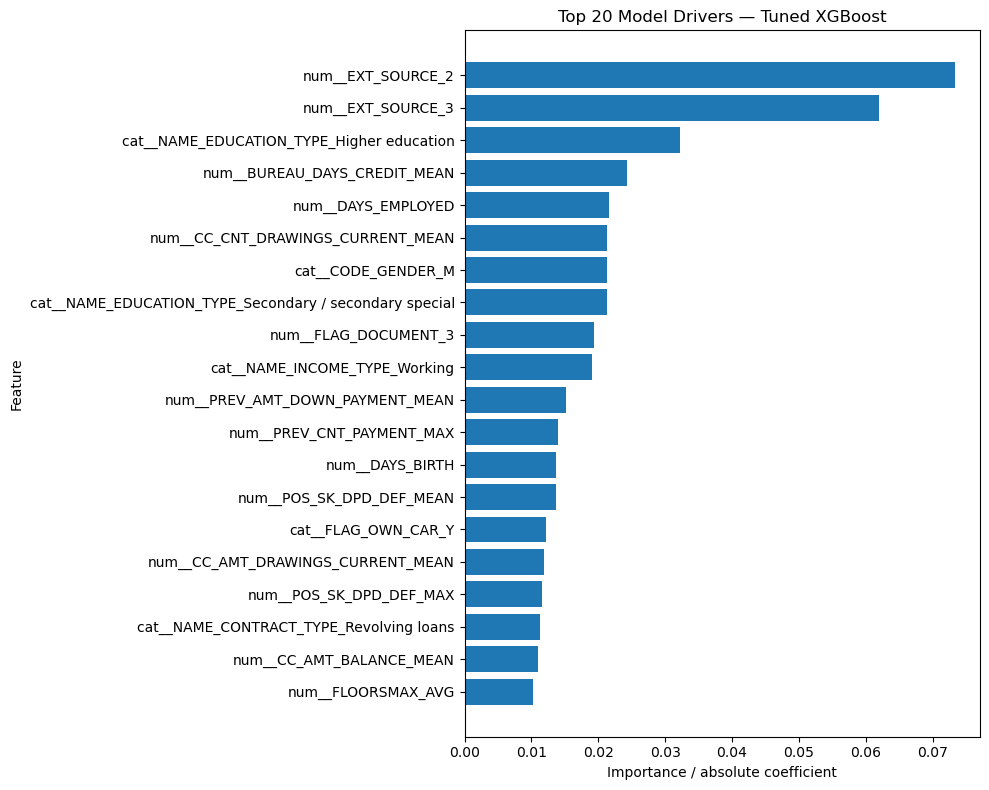

In [217]:

if hasattr(best_model.named_steps['model'], 'feature_importances_'):
    prep = best_model.named_steps['prep']
    feature_names = prep.get_feature_names_out()
    importance = best_model.named_steps['model'].feature_importances_
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importance})
    importance_df = importance_df.sort_values('Importance', ascending=False).head(20)
else:
    prep = best_model.named_steps['prep']
    feature_names = prep.get_feature_names_out()
    coefficients = best_model.named_steps['model'].coef_[0]
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': np.abs(coefficients)})
    importance_df = importance_df.sort_values('Importance', ascending=False).head(20)

display(importance_df)

plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'][::-1], importance_df['Importance'][::-1])
plt.xlabel('Importance / absolute coefficient')
plt.ylabel('Feature')
plt.title(f'Top 20 Model Drivers — {best_model_name}')
plt.tight_layout()
plt.show()


## Final Business Interpretation

- **Accuracy is not the primary decision metric** because only a small fraction of applicants default.
- **Recall** measures how many actual defaulters are identified; **precision** measures how many flagged applicants are actually defaulters.
- **PR-AUC** is especially informative for the minority class, while **ROC-AUC** measures ranking quality across thresholds.
- The validation-selected threshold is used for the final risk flag, making the operating point explicit rather than assuming 0.50 is universally appropriate.
- No rows were removed merely because of IQR outliers; this avoids the excessive sample loss criticized in the earlier project feedback.
- All model preprocessing is fitted on training data only, eliminating a major source of leakage.


In [233]:
def predict_loan_default(
    income, age, employment_years, education, gender, own_car, own_realty,
    family_status, contract_type, region_rating, goods_price,
    ext_source_2=0.5, ext_source_3=0.5
):
    
    row = pd.DataFrame(
        {col: [np.nan] for col in selected_features},
        dtype=object
    )

    assignments = {
        'AMT_INCOME_TOTAL': income,
        'DAYS_BIRTH': -(age * 365),
        'DAYS_EMPLOYED': -(employment_years * 365),
        'REGION_RATING_CLIENT': region_rating,
        'REGION_RATING_CLIENT_W_CITY': region_rating,
        'AMT_GOODS_PRICE': goods_price,
        'EXT_SOURCE_2': ext_source_2,
        'EXT_SOURCE_3': ext_source_3,
        'FLAG_EMP_PHONE': 1
    }

    for col, value in assignments.items():
        if col in row.columns:
            row.at[0, col] = value

    categorical_inputs = {
        'CODE_GENDER': gender,
        'FLAG_OWN_CAR': own_car,
        'FLAG_OWN_REALTY': own_realty,
        'NAME_EDUCATION_TYPE': education,
        'NAME_FAMILY_STATUS': family_status,
        'NAME_CONTRACT_TYPE': contract_type
    }

    for col, value in categorical_inputs.items():
        if col in row.columns:
            row.at[0, col] = value
    probability = float(
        best_model.predict_proba(row[selected_features])[:, 1][0]
    )

    prediction = int(probability >= optimal_threshold)

    result = (
        'HIGHER DEFAULT RISK'
        if prediction == 1
        else 'LOWER DEFAULT RISK'
    )

    print('HOME LOAN DEFAULT RISK PREDICTION')
    print('=' * 50)
    print(f'Default probability : {probability:.2%}')
    print(f'Validation threshold: {optimal_threshold:.2%}')
    print(f'Prediction           : {result}')

    return probability, result

In [235]:

example_probability, example_result = predict_loan_default(
    income=5000000,
    age=25,
    employment_years=3,
    education='Higher education',
    gender='M',
    own_car='Y',
    own_realty='Y',
    family_status='Married',
    contract_type='Cash loans',
    region_rating=2,
    goods_price=40000,
    ext_source_2=0.6,
    ext_source_3=0.6
)


HOME LOAN DEFAULT RISK PREDICTION
Default probability : 25.85%
Validation threshold: 49.33%
Prediction           : LOWER DEFAULT RISK


# Model Comparison Report

The table above is generated from the **freshly trained, leakage-safe models** and should be used as the authoritative result section. It reports accuracy, balanced accuracy, precision, recall, F1, ROC-AUC and PR-AUC.

### Why this is stronger than a single train/test comparison
- Hyperparameters are selected using stratified cross-validation.
- Logistic Regression includes regularization tuning.
- Random Forest and XGBoost are explicitly tuned rather than relying on arbitrary defaults.
- The test set is not used for threshold selection.
- Confusion matrices and classification reports show the actual cost of false positives and false negatives.


# Challenges and How They Were Addressed

1. **Severe class imbalance:** handled with `class_weight='balanced'` / `balanced_subsample` and XGBoost `scale_pos_weight`; evaluation includes PR-AUC, recall and F1 rather than accuracy alone.
2. **Potential data leakage:** train/test split occurs before model-specific imputation, encoding, scaling and correlation filtering; all preprocessing is learned from training data only.
3. **Outliers:** IQR is used for diagnosis, not automatic row deletion. This preserves legitimate high-income/high-credit applicants and avoids excessive sample loss.
4. **Multicollinearity:** highly correlated numerical predictors are screened using the training data only.
5. **Linear-model instability:** regularized Logistic Regression is tuned over multiple `C` values instead of accepting an unstable unregularized solution.
6. **Model-selection uncertainty:** three different model families are compared using stratified cross-validation and an untouched test set.
7. **Threshold choice:** the operating threshold is optimized on a validation split using F2-score, prioritizing recall while retaining precision as a monitored metric.
8. **Data-quality anomaly:** `DAYS_EMPLOYED = 365243` is converted to missing before modeling rather than treated as a genuine employment duration.


# Conclusion

This project follows a complete, defensible machine-learning workflow from multi-table data integration and EDA through leakage-safe preprocessing, feature screening, cross-validated hyperparameter tuning, model comparison, threshold optimization and business-oriented interpretation.

The final model is chosen from the measured results rather than assumed in advance. The notebook also distinguishes between **ranking performance (ROC-AUC/PR-AUC)** and the chosen **operating point (precision/recall/F1)**, which is important for real-world loan-default screening.

### Recommended next steps
- Calibrate predicted probabilities if they will be used as financial risk scores.
- Evaluate the selected threshold against an explicit business cost matrix.
- Add temporal validation if future application dates are available, reducing the risk of performance degradation over time.
- Monitor fairness and stability across important applicant groups before production deployment.
